# 00. WISDM 실험 데이터 이해와 분석
**9week · 2026-11-02 · 데이터 검사 완료 / 모델 학습 전**

이 문서는 “무슨 데이터를 분류하는가?”, “원본에 어떤 문제가 있는가?”, “공정하게 정확도를 비교하려면 무엇을 고정해야 하는가?”를 설명한다. 다음 문서는 [01. CNN 5종 원리와 조합 설계](01_CNN_5종_원리와_조합_설계.ipynb)이다.

> **읽는 기준:** ‘실측’은 제공된 압축파일을 검사한 결과, ‘설명서’는 배포 자료의 명시 내용, ‘제안’은 앞으로 검증할 실험 설정이다. 수치 파싱 가능 레코드 수를 최종 학습 데이터 수로 해석하지 않는다.

모델 정확도, Macro F1, 최적 조합은 **아직 미측정**이다. 이 단계에서 기대 정확도를 임의로 설정하지 않는다.

## 1. 연구 목표와 분류 단위
**학습에 참여하지 않은 사용자의 가속도 구간을 보고 6가지 행동을 분류**하는 것이 주 목표다. 개인별로 이미 학습된 사용자의 다음 행동을 예측하는 개인화 실험과는 평가 목적이 다르다.

원본 레코드 하나는 특정 시점의 가속도 측정값이다. CNN의 분류 단위는 레코드 하나가 아니라 연속 레코드로 구성한 **윈도우**다. 따라서 100만 레코드가 있다는 말은 독립적인 학습 사례가 100만 개라는 뜻이 아니다. 독립적인 사용자도 36명뿐이다.

| 구분 | 의미 | 이번 연구의 사용 |
|---|---|---|
| 원본 레코드 | 한 시점의 센서 측정 | 데이터 품질 검사 |
| 윈도우 | 연속된 여러 시점 | CNN 입력 및 행동 정답 단위 |
| 사용자 | 측정 참여자 | train/validation/test 분리 단위 |
| 연속 구간 | 사용자·행동과 시간 연속성이 유지되는 범위 | 윈도우가 넘으면 안 되는 경계 |

시험 사용자 데이터는 구조·전처리·하이퍼파라미터 선택에 사용하지 않는다.

## 2. 출처와 파일 선택
사용자가 제공한 파일은 `WISDM_ar_latest.tar.gz`이고, 압축 내부 디렉터리는 `WISDM_ar_v1.1`이다. 압축 내부를 직접 읽었으며 원본을 수정하거나 원시 데이터를 새 폴더에 복제하지 않았다.

이 자료는 **WISDM Activity Recognition v1.1**이다. 실험실의 통제된 조건에서 수집된 자료이며, 다른 버전의 스마트폰·스마트워치 WISDM 자료나 실환경 Actitracker 자료와 혼동하지 않는다. [공식 데이터 페이지](https://www.cis.fordham.edu/wisdm/dataset.php)

| 파일 | 내용 | 이번 연구 |
|---|---|---|
| `WISDM_ar_v1.1_raw.txt` | 사용자·행동·시간·3축 가속도 | 주 입력 |
| `WISDM_ar_v1.1_transformed.arff` | 200개 측정값, 명목 10초에서 만든 통계 특징; 설명서상 5,424개 사례·46개 속성 | 주 CNN 입력으로 사용하지 않음 |
| `*_raw_about.txt`, `*_trans_about.txt`, `readme.txt` | 형식, 수집 정보, 인용 안내 | 출처와 파싱 기준 |

통계 특징을 시간순 센서 샘플처럼 Conv1D에 넣으면 특징 열의 순서에 인위적인 이웃 관계를 부여하게 된다. 이번 목적은 원시 시계열의 패턴을 학습하는 것이므로 raw를 사용한다.

배포 설명서는 명목 샘플링을 **20Hz**, 즉 약 **50ms마다 1회**로 안내한다. 중력 성분이 포함된 가속도이며, 설명서의 단위 설명은 “10이 약 1g”이다. 이를 정밀하게 보정된 SI 값이라고 가정하지 않는다.

## 3. 컬럼, 입력 shape, 정답
원본 형식:

```text
user,activity,timestamp,x-acceleration,y-acceleration,z-acceleration;
33,Jogging,49105962326000,-0.6946377,12.680544,0.50395286;
```

| 필드 | 역할 | 모델 입력 포함 |
|---|---|---|
| user | 사용자 ID 1~36, 분할 및 사용자별 평가 | 아니오 |
| activity | 6개 행동 정답 | 입력이 아닌 학습 target |
| timestamp | 일반적으로 기기 가동 후 nanosecond, 시간 연속성 확인 | 아니오 |
| x, y, z | 가속도 3개 축 | 예 |

첫 실험 입력 제안은 `(batch, 128, 3)`이다. 128은 시간 방향 샘플 수, 3은 센서 채널 수다. 20Hz가 유지된다는 가정에서 윈도우 길이를 관례상 128/20 = **6.4초**로 부른다. 실제 첫 샘플과 마지막 샘플 사이 간격은 균일 샘플링이면 127/20초이며, 시간 이상 구간에서는 실제 길이를 따로 확인해야 한다.

첫 합성곱 뒤 `(batch,128,32)`가 되면 32개 채널은 센서 32개가 아니라 **학습된 특징 32개**다. 기존 UCI HAR 노트북의 `(128,9)`를 그대로 사용할 수 없다.

## 4. 파싱 규칙과 수치의 의미
검사 코드는 [scripts/analyze_wisdm.py](scripts/analyze_wisdm.py)에 분리했다. 학습 코드는 포함하지 않는다.

1. 원본을 세미콜론 또는 줄바꿈(CR/LF)으로 나누고 빈 조각을 제외한다.
2. 필드가 7개이며 마지막 필드만 비어 있으면 마지막 빈 필드 1개를 제거한다.
3. 나머지는 6개 필드, 사용자 1~36, 알려진 행동명, 정수 timestamp, 유한한 가속도 3개를 요구한다.
4. 실패 레코드는 원문과 레코드 번호를 기록하고 인접 시간 비교를 끊는다.
5. timestamp가 0이거나 역행하더라도 이번 **품질 검사 집계**에는 남긴다. 중복도 아직 제거하지 않는다.

| 실측 항목 | 수 |
|---|---:|
| 비어 있지 않은 후보 레코드 | 1,098,209 |
| 수치 파싱 가능 레코드 | 1,098,208 |
| 빈 일곱 번째 필드 제거로 복구 | 11,733 |
| 필수 가속도 값 누락으로 파싱 실패 | 1 |
| 모든 6개 필드가 같은 중복의 추가 출현 횟수 | 66,820 |

합계 검증: **1,098,208 + 1 = 1,098,209**. 끝 쉼표 복구 건수는 파싱 가능 레코드에 포함되므로 더하지 않는다.

누락 사례는 `11,Walking,1867172313000,4.4,4.4,`로 z가 비어 있다. 끝 쉼표가 있다고 모두 제거하는 방식은 이 결측과 형식 오류를 혼동할 수 있다.

중복은 숫자로 변환한 `(user, activity, timestamp, x, y, z)` 튜플 기준이다. 동일 튜플이 세 번 나오면 추가 출현 2건으로 센다. 이는 “중복 그룹 수”도, “연속 중복만의 수”도 아니다. 0 timestamp나 세션 반복과의 관계를 확인하기 전 일괄 삭제하지 않는다.

## 5. 공식 수치와 로컬 파일 실측이 다른 이유를 어떻게 다룰 것인가?
공식 요약의 총 레코드 수는 **1,098,207**, 위 규칙으로 읽은 로컬 파일의 유효 수는 **1,098,208**이다. 공식 표에 맞추려고 임의로 행을 제거하지 않는다.

| 행동 | 공식 설명서 | 로컬 수치 파싱 가능 | 차이 |
|---|---:|---:|---:|
| Walking | 424,400 | 424,399 | -1 |
| Jogging | 342,177 | 342,179 | +2 |
| Upstairs | 122,869 | 122,869 | 0 |
| Downstairs | 100,427 | 100,427 | 0 |
| Sitting | 59,939 | 59,939 | 0 |
| Standing | 48,395 | 48,395 | 0 |
| 합계 | 1,098,207 | 1,098,208 | +1 |

Walking의 차이는 확인된 결측 1건과 일치한다. **Jogging의 +2가 발생한 배포·집계상의 원인은 아직 확정하지 않았다.** 중복 66,820건과 이 +2를 같은 문제라고 설명하지 않는다. 현재 보고서는 로컬 파일 fingerprint와 파서 규칙에 근거해 재현 가능한 실측을 사용한다.

[검사 JSON](artifacts/data_audit.json)에 압축파일과 raw의 SHA-256을 기록했다. 다른 환경에서 결과가 다르면 파일 hash와 파서부터 비교한다.

## 6. 행동 분포: Accuracy만으로 부족한 이유
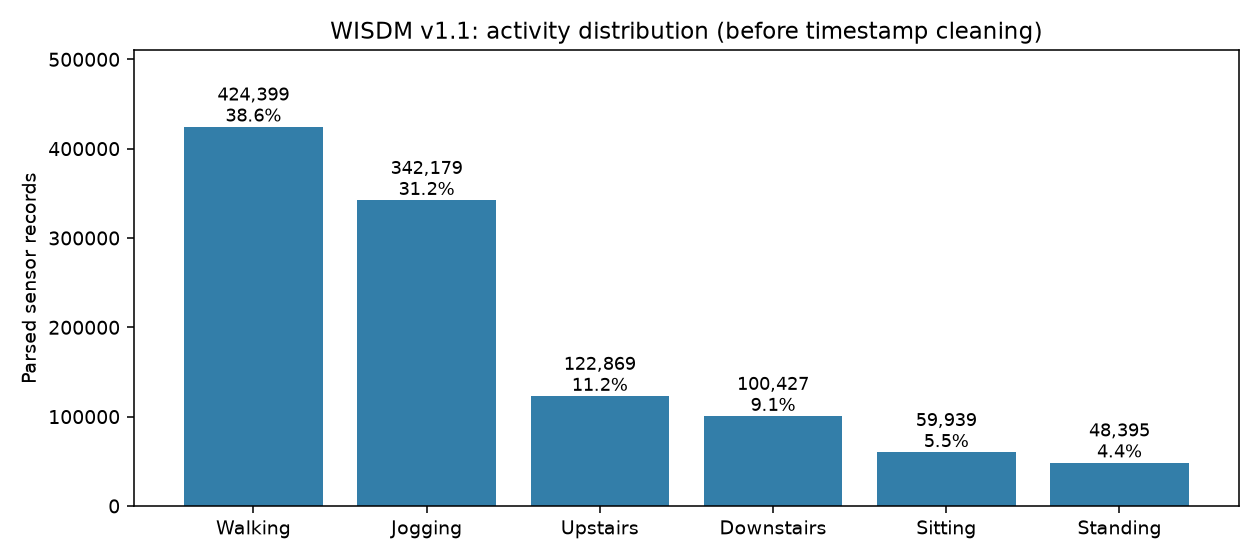

Walking과 Jogging을 합치면 약 **69.8%**다. 이는 정제 전 **센서 레코드 분포**이며, 최종 윈도우 분포와 같다고 보장되지 않는다.

Accuracy는 전체 윈도우 중 맞힌 비율이다. 데이터가 많은 행동에서 개선되고 Standing 같은 소수 행동에서 악화되어도 Accuracy는 오를 수 있다. 항상 Walking이라고 답하는 레코드 수준 기준의 비율은 약 38.6%지만, 이를 향후 윈도우 기반 모델의 baseline 정확도로 그대로 사용하지 않는다.

**평가 제안**
- Accuracy: 전체 예측 정확도.
- Macro F1: 6개 행동의 F1을 같은 비중으로 평균. 모델 선택의 기본 지표로 사용.
- 행동별 precision/recall/F1, confusion matrix: 어떤 행동에서 오탐·미탐이 생기는지 확인.
- 사용자별 성능: 전체 평균이 일부 사용자 실패를 가리지 않는지 확인.

Class weight는 **train 윈도우 분포**로만 계산하고, 구조 비교 후 별도 실험으로 검증한다. 전체 데이터 분포로 가중치를 계산하지 않는다.

## 7. 사용자별 분포: 사용자 분할에 필요한 근거
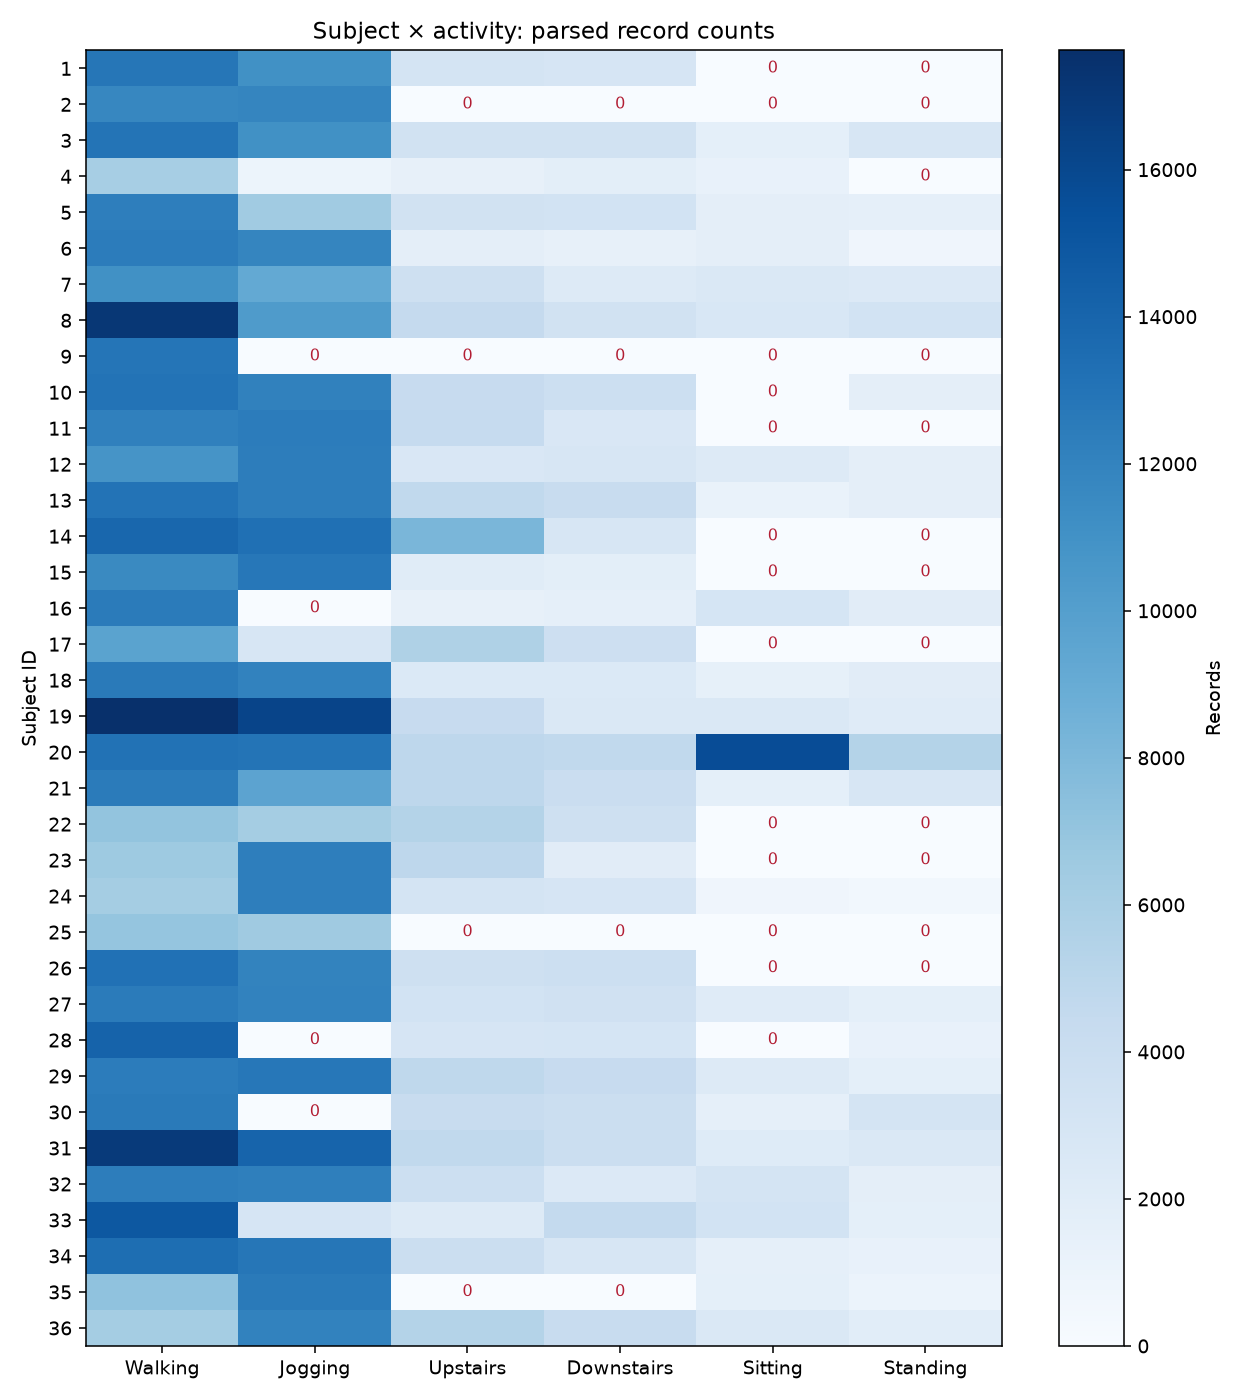

36명 모두 레코드는 있지만 **17명은 6가지 행동 중 일부가 없다.** 그림의 빨간 0은 해당 사용자의 그 행동이 없음을 뜻한다. 예를 들어 사용자 9는 Walking만, 사용자 2와 25는 Walking/Jogging만 있다.

따라서 사용자 수만 맞춰 무작위로 나누면 특정 split의 행동 분포가 심하게 치우치거나 행동이 누락될 수 있다. 사용자 단위 분할을 유지하면서 각 split의 행동 존재 여부와 윈도우 수를 검증해야 한다.

사용자별 전체 목록은 [data_audit.json](artifacts/data_audit.json)의 `subject_class_counts`, `missing_classes_by_subject`에 있다.

**해석의 한계:** 이 자료에서 좋은 성능이 나와도 다른 기기, 휴대 위치, 자유로운 실생활 조건의 성능을 바로 보장하지 않는다. 사용자 일반화 실험과 실환경 일반화 실험은 구별한다.

## 8. 시간 품질: 20Hz라고 모든 간격이 50ms는 아니다
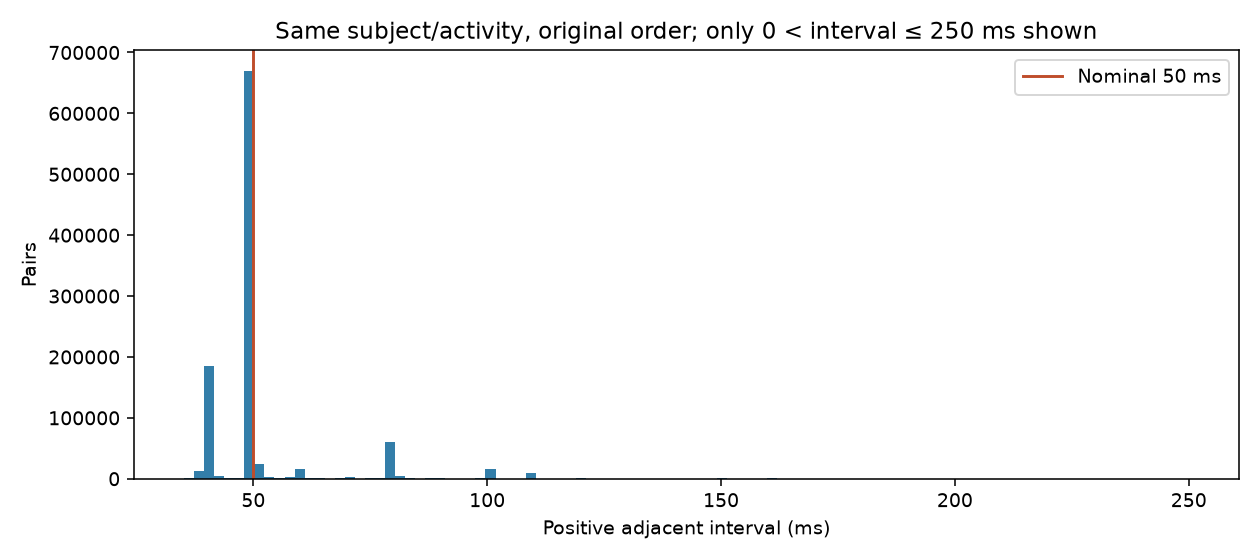

위 그래프는 **0 < 간격 ≤ 250ms인 쌍만 표시**한다. 0·음수·큰 공백은 아래 표로 별도 보고한다. 그래프만 보고 모든 레코드가 정상이라고 해석하지 않는다.

| 항목 | 실측 |
|---|---:|
| timestamp=0인 레코드 | 12,845 |
| 같은 사용자·행동의 원본 인접 쌍 | 1,097,803 |
| 그중 시간차=0 | 47,588 |
| 그중 시간차<0 | 7,467 |
| 그중 시간차>250ms | 8,022 |
| 양수 시간차 중앙값 | 49.988ms |
| 양수 시간차 99백분위 | 약 120.148ms |

레코드 수와 인접 쌍 수는 다른 단위다. timestamp=0인 레코드 수를 나머지 수치와 합산하지 않는다. 인접 쌍은 사용자·행동이 바뀌거나 파싱에 실패하면 연결하지 않았다. 공식 session ID가 없어 같은 사용자·행동이라고 같은 세션이라는 보장은 없다.

**전처리 제안:** 사용자/행동 변경, 결측, timestamp 0·중복·역행, 큰 공백에서 경계를 만든다. 전체 파일을 timestamp로 정렬해 서로 다른 세션을 연결하지 않는다. 250ms는 검사 임계값이며 확정된 최적 전처리 임계값이 아니다.

보수적으로 경계를 나누면 짧은 구간이 많이 생길 수 있다. 최종 정책 선택 전 반드시 **사용자·행동별 남은 레코드/윈도우 수**를 비교해야 한다. 원본 순서 기반 윈도우 정책과의 비교는 validation에서만 수행하고, 최종 test 결과를 보고 정책을 바꾸지 않는다.

## 9. 가속도 범위와 정규화의 의미
아래는 전체 수치 파싱 가능 레코드의 기술 통계다. 학습용 정규화 통계로 재사용하지 않는다.

| 축 | 최솟값 | 1백분위 | 중앙값 | 99백분위 | 최댓값 |
|---|---:|---:|---:|---:|---:|
| x | -19.61 | -19.04 | 0.27 | 19.00 | 19.95 |
| y | -19.61 | -12.79 | 7.93 | 19.57 | 20.04 |
| z | -19.80 | -11.99 | 0.00 | 13.33 | 19.61 |

축별 분포가 다르고 중력 성분도 포함된다. 이 통계만으로 특정 축이 더 중요하다거나 신호가 포화됐다고 단정하지 않는다. 설명서의 약 -20~20 범위를 약간 넘는 값도 있으므로 자동 clipping하지 않는다.

**제안:** train의 정제된 원본 샘플만으로 축별 평균·표준편차를 계산한 후 validation/test에 같은 값을 적용한다. 겹친 윈도우에서 같은 샘플이 반복 계산되지 않게 원본 샘플을 기준으로 한다.

윈도우마다 평균을 빼면 절대적인 자세·중력 방향 정보가 사라질 수 있다. 초기 기본값으로 사용하지 않고 별도 전처리 실험으로 둔다. 가속도 크기 채널 추가, 회전 증강, 보간 역시 기본 구조 비교와 동시에 바꾸지 않는다.

## 10. 데이터에서 모델 평가까지의 제안 과정
```text
원본 형식 복구 및 품질 기록
→ 사용자 단위 train / validation / test 분할
→ 각 split 안에서 연속 구간 확인 및 정제
→ train 원본 샘플로 정규화 통계 계산
→ 구간 안에서만 윈도우 생성
→ 동일 입력·학습 조건으로 모델 비교
→ validation으로 선택
→ 확정한 모델을 잠근 test에서 최종 평가
```

| 항목 | 시작 제안 | 이유 / 상태 |
|---|---|---|
| 사용자 분할 | 24/6/6명 | 예시 비율; ID 목록은 아직 미선정 |
| 윈도우 길이 | 128 샘플 | 명목 6.4초; 64/200은 후속 비교 |
| stride | train 64, validation/test 128 | 학습 다양성 확보, 평가 중복 감소 |
| 경계 | 사용자·행동·시간 연속성 | 서로 다른 구간이 한 입력으로 섞이지 않게 함 |
| 보간 | 초기 baseline에서는 사용하지 않음 | 임의의 신호 생성 효과와 구조 효과 분리 |
| 표준화 | train 기준 축별 통계 | 평가 데이터의 정보 사용 방지 |
| 클래스 불균형 처리 | 첫 구조 비교는 동일한 무가중 손실 | 가중치 효과는 독립 검증 |
| 모델 선택 | validation Macro F1 | 소수 행동 성능도 반영 |
| 최종 보고 | Accuracy, Macro F1, 행동별/사용자별 성능 | 개선 원인 및 편차 확인 |

행동 label로 경계를 나누는 것은 정답이 주어진 정적 HAR 분류 benchmark의 설정이다. 실제 스트리밍 환경에서 행동 전환을 탐지하는 과제와는 다르다. 향후 전환 구간 실험은 별도로 정의한다.

겹치는 윈도우를 만든 뒤 무작위 분할하면 거의 같은 신호가 학습·평가에 함께 들어갈 수 있다. **사용자 분할을 먼저 수행**하는 이유다.

## 11. 분석 코드가 연구에 기여하는 방식과 재현
설명과 코드를 분리했지만 각 계산의 목적은 명확히 연결한다.

| 구현 기능 | 필요한 이유 | 연결되는 연구 판단 |
|---|---|---|
| 엄격한 파싱 + 끝 쉼표 복구 | 오류 때문에 정상 데이터를 대량 손실하지 않게 함 | 비교 모델에 동일 데이터 제공 |
| 사용자×행동 집계 | 누락 행동과 불균형 확인 | 분할 가능성, Macro F1 해석 |
| 시간차 및 중복 검사 | 잘못된 윈도우와 반복 사례 파악 | 성능 과대평가 및 전처리 영향 점검 |
| 가속도 기술 통계 | 분포와 값 범위 확인 | 정규화·clipping 가정 검토 |
| SHA-256 및 JSON 저장 | 같은 데이터·규칙임을 확인 | 반복 연구의 재현성 |
| 그래프 생성 | 큰 표에서 패턴 확인 | 편향과 품질 문제 설명 |

저장소 루트에서 실행:

```powershell
python -m pip install numpy matplotlib nbformat
python 9week/scripts/analyze_wisdm.py
```

다른 위치의 압축파일을 사용하려면 `--archive "절대경로"`, 별도 결과 폴더는 `--output "경로"`를 지정한다. 파일 기본 경로는 제공된 Downloads 경로다. 원본은 읽기만 하며 집계와 그림만 출력한다.

그림은 이 노트북에 첨부되어 있어 노트북만 열어도 표시된다. 원본 PNG와 JSON은 `artifacts`에 남긴다. 분석을 재실행한 뒤 문서를 다시 생성하려면 `python 9week/scripts/build_notebooks.py`를 실행한다.

이 검사는 파싱·집계 검사이지 최종 학습 전처리가 아니다. 정제 전 수치가 바뀌면 문서와 그림도 함께 갱신해야 한다.

## 12. 현재 결론, 남은 결정, 다음 문서
**확인 완료:** 데이터 형식, 36명·6행동·3축 구성, 파싱 가능 수, 형식 복구와 결측, 불균형, 사용자별 행동 누락, 시간 이상, 정확한 필드 중복, 가속도 범위.

**아직 결정/측정하지 않은 것:** 최종 중복·시간 이상 처리 정책, 정제 후 윈도우 수, 사용자 split ID, 학습 결과와 최적 조합. 사용자별 유지율을 확인하고 학습 전 프로토콜에 고정해야 한다.

다음 [01 문서](01_CNN_5종_원리와_조합_설계.ipynb)는 이 데이터의 특성에 어떤 CNN 구성 요소가 대응하는지와, 각 조합의 효과를 구분하는 실험을 설명한다.

## 참고 자료
- WISDM Lab, [Activity Recognition Dataset](https://www.cis.fordham.edu/wisdm/dataset.php): 버전·공식 통계·자료 인용 안내. 확인일 2026-11-02.
- Kwapisz, J. R., Weiss, G. M., & Moore, S. A. (2010 workshop), [Activity Recognition using Cell Phone Accelerometers](https://www.cis.fordham.edu/wisdm/public_files/sensorKDD-2010.pdf): 데이터 제공처가 인용을 요청한 원 연구. 서지 연도는 배포 readme 표기를 따랐다.
- 원본 `readme.txt`, `*_raw_about.txt`, `*_trans_about.txt`의 내용을 [source_descriptions.json](artifacts/source_descriptions.json)에 보존했다.
- 현재 파일의 분석 결과: [data_audit.json](artifacts/data_audit.json). 웹의 공식 숫자가 아니라 이 로컬 파일의 실측을 분석 표에 사용했다.